# 08 · Census linking: do enrolled participants reflect the people near the sites?

**Focused component (Role Y), part 2 of 2.** Builds on `06_representation_data` (enrolled shares) and
`03_eligibility_features` (strictness).

1. Map each U.S. site's ZIP code to its county (Census 2020 ZCTA–county relationship file).
2. Pull county population shares by sex, race, Hispanic ethnicity and age from the **ACS 5-year** estimates.
3. For each trial, average the shares of its sites' counties → the trial's **local population**.
4. Compute the **participation-to-prevalence ratio**: `PPR = enrolled share ÷ local population share`
   (1 = proportional; below 0.8 is commonly read as under-representation).
5. Test whether **stricter eligibility** is associated with lower PPR, adjusting for phase, sponsor,
   start year, trial size and healthy volunteers.

Census files are downloaded once and cached in `data/raw/census/` (git-ignored). No API key is needed
for this volume; if you have one, set `CENSUS_API_KEY` in `.env`.

In [1]:
import json
import os
import urllib.parse
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from dotenv import load_dotenv

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "notebooks" / "figures"
CENSUS = RAW / "census"
CENSUS.mkdir(parents=True, exist_ok=True)
load_dotenv(ROOT / ".env")

ACS_YEAR = 2020            # ACS 2016-2020 5-year: 2020 county lines, end of the 2008-2020 cohort
MIN_SITES_MATCHED = 0.5    # keep trials whose sites are at least this share matched to a county
MIN_ENROLLED = 20          # minimum participants for the PPR analysis (small trials give noisy ratios)
UNDER, OVER = 0.8, 1.2     # PPR thresholds for under / over-representation
MAIN_SET = "completed"     # "completed" (successfully enrolled) or "all" (any trial with posted results)

## 1. Load representation data (from notebook 06)

In [2]:
rep = pd.read_parquet(PROC / "representation_trials.parquet")
sites = pd.read_parquet(PROC / "us_sites.parquet")
print(f"{len(rep):,} trials, {len(sites):,} sites ({sites['zip5'].notna().mean():.1%} with ZIP)")

26,959 trials, 208,469 sites (94.2% with ZIP)


## 2. ZIP → county

The Census publishes how each ZIP Code Tabulation Area (ZCTA) overlaps counties. A ZIP that spans
counties is assigned to the county holding most of its land area. U.S. Postal ZIPs and ZCTAs mostly
coincide; PO-box-only ZIPs have no ZCTA and stay unmatched.

In [3]:
REL_URL = ("https://www2.census.gov/geo/docs/maps-data/data/rel2020/zcta520/"
           "tab20_zcta520_county20_natl.txt")
rel_path = CENSUS / "tab20_zcta520_county20_natl.txt"
if not rel_path.exists():
    print("Downloading ZCTA-county relationship file ...")
    urllib.request.urlretrieve(REL_URL, rel_path)

rel = pd.read_csv(rel_path, sep="|", dtype=str)
rel = rel.dropna(subset=["GEOID_ZCTA5_20", "GEOID_COUNTY_20"])
rel["AREALAND_PART"] = pd.to_numeric(rel["AREALAND_PART"], errors="coerce")
zip2county = (rel.sort_values("AREALAND_PART", ascending=False)
                 .drop_duplicates("GEOID_ZCTA5_20")
                 .set_index("GEOID_ZCTA5_20")["GEOID_COUNTY_20"])
print(f"{zip2county.size:,} ZCTAs -> {zip2county.nunique():,} counties")

sites["county_fips"] = sites["zip5"].map(zip2county)
print(f"Sites matched to a county: {sites['county_fips'].notna().mean():.1%}")

33,791 ZCTAs -> 3,211 counties
Sites matched to a county: 89.9%


## 3. County population from the ACS

| Measure | ACS table | Share used |
|---|---|---|
| Female | B01001 | female ÷ total |
| Race | B02001 | each NIH/OMB race ÷ (all races except "Some other race") |
| Hispanic | B03003 | Hispanic ÷ total |
| Age 65+ | B01001 | 65+ ÷ adults 18+ |

"Some other race" is left out of the race denominator because the NIH/OMB race question in
ClinicalTrials.gov has no such category (see limitations).

In [4]:
male_u18 = [f"B01001_{i:03d}E" for i in range(3, 7)]
fem_u18 = [f"B01001_{i:03d}E" for i in range(27, 31)]
male_65 = [f"B01001_{i:03d}E" for i in range(20, 26)]
fem_65 = [f"B01001_{i:03d}E" for i in range(44, 50)]
VARS = {
    "B01001_001E": "pop", "B01001_026E": "female",
    "B02001_002E": "white", "B02001_003E": "black", "B02001_004E": "aian",
    "B02001_005E": "asian", "B02001_006E": "nhpi", "B02001_007E": "other_race", "B02001_008E": "multi",
    "B03003_001E": "eth_total", "B03003_003E": "hispanic",
    **{v: v for v in male_u18 + fem_u18 + male_65 + fem_65},
}

acs_path = CENSUS / f"acs5_{ACS_YEAR}_county.csv"
if not acs_path.exists():
    params = {"get": ",".join(["NAME", *VARS]), "for": "county:*"}
    if os.getenv("CENSUS_API_KEY"):
        params["key"] = os.getenv("CENSUS_API_KEY")
    url = f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5?" + urllib.parse.urlencode(params)
    print("Downloading ACS county data ...")
    with urllib.request.urlopen(url, timeout=120) as resp:
        rows = json.load(resp)
    pd.DataFrame(rows[1:], columns=rows[0]).to_csv(acs_path, index=False)

acs = pd.read_csv(acs_path, dtype={"state": str, "county": str})
acs["county_fips"] = acs["state"].str.zfill(2) + acs["county"].str.zfill(3)
acs = acs.rename(columns=VARS)
num = [c for c in acs.columns if c not in ("NAME", "state", "county", "county_fips")]
acs[num] = acs[num].apply(pd.to_numeric, errors="coerce")

race_den = acs[["white", "black", "aian", "asian", "nhpi", "multi"]].sum(axis=1)
under18 = acs[male_u18 + fem_u18].sum(axis=1)
pop_local = pd.DataFrame({
    "county_fips": acs["county_fips"],
    "pop": acs["pop"],
    "local_female": acs["female"] / acs["pop"],
    **{f"local_{r}": acs[r] / race_den for r in ["white", "black", "asian"]},
    "local_hispanic": acs["hispanic"] / acs["eth_total"],
    "local_65plus_adults": acs[male_65 + fem_65].sum(axis=1) / (acs["pop"] - under18),
})
print(f"{len(pop_local):,} counties")
pop_local.describe().round(3)

3,221 counties


,pop,local_female,local_white,local_black,local_asian,local_hispanic,local_65plus_adults
count,3.221000e+03,3221.000,3221.000,3221.000,3221.000,3221.000,3221.000
mean,1.023983e+05,0.500,0.833,0.093,0.014,0.117,0.246
std,3.282634e+05,0.025,0.167,0.148,0.030,0.194,0.055
min,1.170000e+02,0.291,0.033,0.000,0.000,0.000,0.021
25%,1.112500e+04,0.494,0.776,0.007,0.003,0.024,0.211
50%,2.598100e+04,0.504,0.900,0.025,0.006,0.045,0.243
75%,6.696900e+04,0.512,0.950,0.106,0.014,0.107,0.275
max,1.004068e+07,0.580,1.000,0.899,0.434,1.000,0.623


## 4. Each trial's local population

Each matched site counts equally (sites, not counties, recruit participants). A population-weighted
version over the trial's distinct counties is kept as a sensitivity check.

In [5]:
LOCAL = ["local_female", "local_white", "local_black", "local_asian", "local_hispanic", "local_65plus_adults"]

s = sites.merge(pop_local, on="county_fips", how="left")
match = s.groupby("nct_id").agg(n_sites=("nct_id", "size"),
                                n_matched=("county_fips", lambda x: x.notna().sum()),
                                n_counties=("county_fips", "nunique"))
match["pct_matched"] = match["n_matched"] / match["n_sites"]

local_site = s.dropna(subset=["county_fips"]).groupby("nct_id")[LOCAL].mean()

uc = s.dropna(subset=["county_fips"]).drop_duplicates(["nct_id", "county_fips"])
local_pop = (uc[LOCAL].multiply(uc["pop"], axis=0).groupby(uc["nct_id"]).sum()
               .div(uc.groupby("nct_id")["pop"].sum(), axis=0)
               .add_suffix("_popw"))

df = (rep.merge(match, on="nct_id", how="left")
         .merge(local_site, on="nct_id", how="left")
         .merge(local_pop, on="nct_id", how="left"))
df = df[(df["pct_matched"] >= MIN_SITES_MATCHED) & (df["n_enrolled"] >= MIN_ENROLLED)]
if MAIN_SET == "completed":
    df = df[df["completed"]]
print(f"Trials in the PPR analysis: {len(df):,}  (main set: {MAIN_SET}, >= {MIN_ENROLLED} participants, "
      f">= {MIN_SITES_MATCHED:.0%} of sites matched)")

Trials in the PPR analysis: 18,552  (main set: completed, >= 20 participants, >= 50% of sites matched)


## 5. Participation-to-prevalence ratio (PPR)

In [6]:
GROUPS = {  # label: (enrolled share, local share, enrolled count, enrolled denominator)
    "Female":   ("share_female", "local_female", "sex_female_n", ["sex_female_n", "sex_male_n"]),
    "White":    ("share_white", "local_white", "race_white_n",
                 [f"race_{x}_n" for x in ["white", "black", "asian", "aian", "nhpi", "multi"]]),
    "Black":    ("share_black", "local_black", "race_black_n",
                 [f"race_{x}_n" for x in ["white", "black", "asian", "aian", "nhpi", "multi"]]),
    "Asian":    ("share_asian", "local_asian", "race_asian_n",
                 [f"race_{x}_n" for x in ["white", "black", "asian", "aian", "nhpi", "multi"]]),
    "Hispanic": ("share_hispanic", "local_hispanic", "eth_hispanic_n", ["eth_hispanic_n", "eth_not_hispanic_n"]),
    "Age 65+":  ("share_65plus_adults", "local_65plus_adults", "age_65plus_n", ["age_18_64_n", "age_65plus_n"]),
}

# Age 65+ only makes sense for trials whose eligibility allows older adults
if "older_adult" in df.columns:
    allows_65 = df["older_adult"].astype("string").str.lower().isin(["true", "t", "1", "yes"])
    df.loc[~allows_65, ["share_65plus_adults", "age_65plus_n"]] = np.nan

for g, (enr, loc, n_col, den_cols) in GROUPS.items():
    k = g.lower().replace(" ", "").replace("+", "plus")
    df[loc] = df[loc].where(df[loc] > 0)
    df[f"{loc}_popw"] = df[f"{loc}_popw"].where(df[f"{loc}_popw"] > 0)
    df[f"ppr_{k}"] = df[enr] / df[loc]
    df[f"ppr_{k}_popw"] = df[enr] / df[f"{loc}_popw"]
    # log PPR with a 0.5 continuity correction so trials with zero participants of a group stay in
    den = df[den_cols].sum(axis=1, min_count=1)
    adj = (df[n_col] + 0.5) / (den + 1)
    df[f"logppr_{k}"] = np.log(adj / df[loc]).where(df[enr].notna())

df = df.replace([np.inf, -np.inf], np.nan)

PPR = {g: f"ppr_{g.lower().replace(' ', '').replace('+', 'plus')}" for g in GROUPS}

def summarize(col_map, data):
    out = {}
    for g, c in col_map.items():
        x = data[c].dropna()
        out[g] = {"trials": len(x), "median PPR": x.median(),
                  "IQR": f"{x.quantile(.25):.2f}–{x.quantile(.75):.2f}",
                  f"% under (<{UNDER})": (x < UNDER).mean(), f"% over (>{OVER})": (x > OVER).mean(),
                  "pooled PPR": (data.loc[x.index, GROUPS[g][2]].sum()
                                 / data.loc[x.index, GROUPS[g][3]].sum().sum()
                                 / data.loc[x.index, GROUPS[g][1]].mean())}
    return pd.DataFrame(out).T

ppr_table = summarize(PPR, df)
fmt = {"trials": "{:,.0f}", "median PPR": "{:.2f}", "pooled PPR": "{:.2f}",
       f"% under (<{UNDER})": "{:.1%}", f"% over (>{OVER})": "{:.1%}"}
display(ppr_table.style.format(fmt))
ppr_table.to_csv(PROC / "ppr_summary.csv")

,trials,median PPR,IQR,% under (<0.8),% over (>1.2),pooled PPR
Female,"18,552",0.98,0.70–1.32,32.7%,31.7%,1.02
White,"9,404",1.19,0.98–1.38,14.1%,48.1%,1.18
Black,"9,401",0.68,0.27–1.42,55.5%,30.4%,0.85
Asian,"9,403",0.21,0.00–0.59,82.8%,9.9%,0.37
Hispanic,"7,516",0.51,0.22–0.95,68.3%,17.2%,0.72
Age 65+,"4,858",1.04,0.03–2.44,45.0%,47.3%,1.70


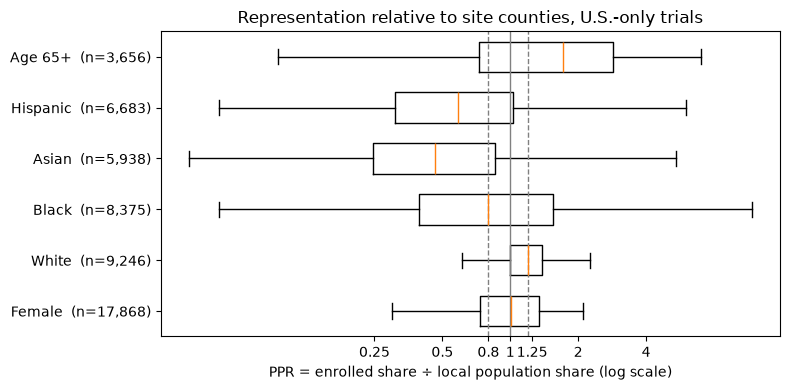

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [np.log2(df[c].replace(0, np.nan).dropna()) for c in PPR.values()]
ax.boxplot(data, orientation="horizontal", showfliers=False, widths=0.6)
ax.set_yticks(range(1, len(PPR) + 1), [f"{g}  (n={len(d):,})" for g, d in zip(PPR, data)])
for v, ls in [(0, "-"), (np.log2(UNDER), "--"), (np.log2(OVER), "--")]:
    ax.axvline(v, color="gray", ls=ls, lw=1)
ticks = [0.25, 0.5, 0.8, 1, 1.25, 2, 4]
ax.set_xticks(np.log2(ticks), [str(t) for t in ticks])
ax.set_xlabel("PPR = enrolled share ÷ local population share (log scale)")
ax.set_title("Representation relative to site counties, U.S.-only trials")
plt.tight_layout(); plt.savefig(FIG / "rep_ppr_by_group.png", dpi=200); plt.show()

In [8]:
# Sensitivity: site-weighted vs population-weighted local population
sens = pd.DataFrame({
    "median PPR (site-weighted)": [df[c].median() for c in PPR.values()],
    "median PPR (population-weighted)": [df[f"{c}_popw"].median() for c in PPR.values()],
}, index=list(PPR))
sens.round(2)

,median PPR (site-weighted),median PPR (population-weighted)
Female,0.98,0.99
White,1.19,1.21
Black,0.68,0.70
Asian,0.21,0.19
Hispanic,0.51,0.45
Age 65+,1.04,1.06


## 6. Is stricter eligibility linked to bigger gaps?

**Strictness** comes from notebook 03 when its output is available; otherwise criteria length
(log₂ characters) is used, the same proxy as the termination analysis. Each model regresses log PPR on
strictness (standardized, so the coefficient is per 1 SD) plus phase, lead sponsor class, start year,
log trial size and healthy volunteers, with robust (HC3) standard errors.
`exp(coef)` is the multiplicative change in PPR per 1 SD stricter criteria.

In [9]:
# ---- strictness from notebook 03 -------------------------------------------------------------
STRICTNESS_FILE = None          # e.g. PROC / "eligibility_features.parquet" (auto-detected if None)
STRICTNESS_COL = None           # e.g. "strictness_score" (auto-detected if None)

def find_strictness():
    cands = [STRICTNESS_FILE] if STRICTNESS_FILE else sorted(PROC.glob("*.parquet"))
    for f in cands:
        if f is None or not Path(f).exists():
            continue
        cols = pd.read_parquet(f).columns
        hit = STRICTNESS_COL if STRICTNESS_COL in cols else next((c for c in cols if "strict" in c.lower()), None)
        if hit and "nct_id" in cols:
            return pd.read_parquet(f, columns=["nct_id", hit]).rename(columns={hit: "strictness"}), f"{Path(f).name}:{hit}"
    return None, None

strict, source = find_strictness()
if strict is not None:
    df = df.drop(columns=["strictness"], errors="ignore").merge(strict.drop_duplicates("nct_id"), on="nct_id", how="left")
    print(f"Strictness from {source}; available for {df['strictness'].notna().mean():.1%} of trials")
else:
    df["strictness"] = np.log2(df["criteria_n_chars"])
    source = "log2(criteria length) [proxy: notebook 03 output not found]"
    print("Notebook 03 strictness not found in data/processed/; using log2(criteria length).")
    print("Set STRICTNESS_FILE / STRICTNESS_COL above once Neha's output is saved.")
df["strict_z"] = (df["strictness"] - df["strictness"].mean()) / df["strictness"].std()
df["crit_len_z"] = np.log2(df["criteria_n_chars"])
df["crit_len_z"] = (df["crit_len_z"] - df["crit_len_z"].mean()) / df["crit_len_z"].std()

Strictness from representation_ppr.parquet:strictness; available for 100.0% of trials


In [10]:
# ---- covariates ---------------------------------------------------------------------------
def collapse(s, min_n=30, other="OTHER"):
    s = s.fillna("MISSING").astype(str)
    vc = s.value_counts()
    return s.where(s.map(vc) >= min_n, other)

df["phase_c"] = collapse(df["phase"])
df["sponsor_c"] = collapse(df["lead_sponsor_class"])
hv = df["healthy_volunteers"].astype("string").str.lower()
df["healthy_vol"] = hv.isin(["true", "t", "yes", "accepts healthy volunteers", "1"]).astype(int)
df["log_n"] = np.log(df["n_enrolled"])
df["year_c"] = df["start_year"] - 2014

COVARS = "C(phase_c) + C(sponsor_c) + year_c + log_n + healthy_vol"

def fit_all(exposure, data):
    rows = []
    for g in GROUPS:
        k = g.lower().replace(" ", "").replace("+", "plus")
        y = f"logppr_{k}"
        sub = data.dropna(subset=[y, exposure, "start_year"])
        if len(sub) < 50:
            continue
        m = smf.ols(f"{y} ~ {exposure} + {COVARS}", data=sub).fit(cov_type="HC3")
        b, (lo, hi) = m.params[exposure], m.conf_int().loc[exposure]
        rows.append({"group": g, "n": int(m.nobs), "PPR ratio per 1 SD": np.exp(b),
                     "95% CI": f"{np.exp(lo):.3f}–{np.exp(hi):.3f}", "p": m.pvalues[exposure],
                     "lo": np.exp(lo), "hi": np.exp(hi)})
    return pd.DataFrame(rows).set_index("group")

res = fit_all("strict_z", df)
print(f"Exposure: {source}")
display(res.drop(columns=["lo", "hi"]).style.format({"n": "{:,}", "PPR ratio per 1 SD": "{:.3f}", "p": "{:.3g}"}))
res.to_csv(PROC / "ppr_strictness_models.csv")

Exposure: representation_ppr.parquet:strictness


,n,PPR ratio per 1 SD,95% CI,p
group,,,,
Female,"18,552",0.977,0.962–0.992,0.00344
White,"9,404",1.074,1.056–1.093,8.24e-16
Black,"9,401",0.912,0.887–0.938,8.75e-11
Asian,"9,403",1.020,0.994–1.047,0.128
Hispanic,"7,516",0.920,0.896–0.944,4.63e-10
Age 65+,"4,858",1.108,1.047–1.172,0.000358


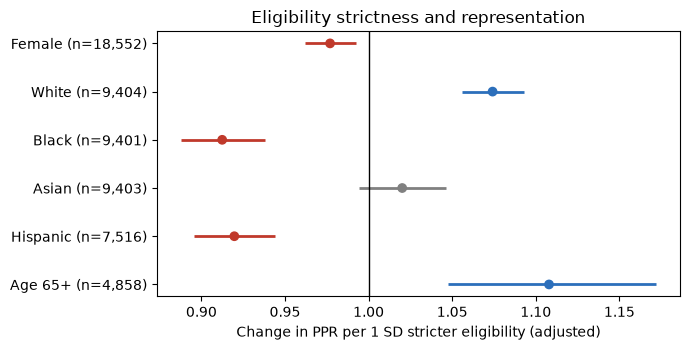

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(res))[::-1]
sig = (res["lo"] > 1) | (res["hi"] < 1)
colors = np.where(~sig, "gray", np.where(res["PPR ratio per 1 SD"] < 1, "#c0392b", "#2c6fbb"))
ax.errorbar(res["PPR ratio per 1 SD"], y, xerr=[res["PPR ratio per 1 SD"] - res["lo"], res["hi"] - res["PPR ratio per 1 SD"]],
            fmt="none", ecolor=colors, elinewidth=2)
ax.scatter(res["PPR ratio per 1 SD"], y, c=colors, zorder=3)
ax.axvline(1, color="black", lw=1)
ax.set_yticks(y, [f"{g} (n={n:,})" for g, n in zip(res.index, res["n"])])
ax.set_xlabel("Change in PPR per 1 SD stricter eligibility (adjusted)")
ax.set_title("Eligibility strictness and representation")
plt.tight_layout(); plt.savefig(FIG / "rep_strictness_forest.png", dpi=200); plt.show()

In [12]:
# ---- robustness ---------------------------------------------------------------------------
checks = {
    "Main": res["PPR ratio per 1 SD"],
    "Criteria length instead": fit_all("crit_len_z", df)["PPR ratio per 1 SD"],
    "Race unknown <= 10%": fit_all("strict_z", df[df["race_unknown_pct"].fillna(0) <= 0.10])["PPR ratio per 1 SD"],
    "No total mismatch": fit_all("strict_z", df[~df["flag_total_mismatch"]])["PPR ratio per 1 SD"],
}
pd.DataFrame(checks).round(3)

,Main,Criteria length instead,Race unknown <= 10%,No total mismatch
group,,,,
Female,0.977,0.977,0.979,0.978
White,1.074,1.074,1.080,1.074
Black,0.912,0.912,0.915,0.915
Asian,1.020,1.020,1.018,1.020
Hispanic,0.920,0.920,0.927,0.919
Age 65+,1.108,1.108,1.112,1.109


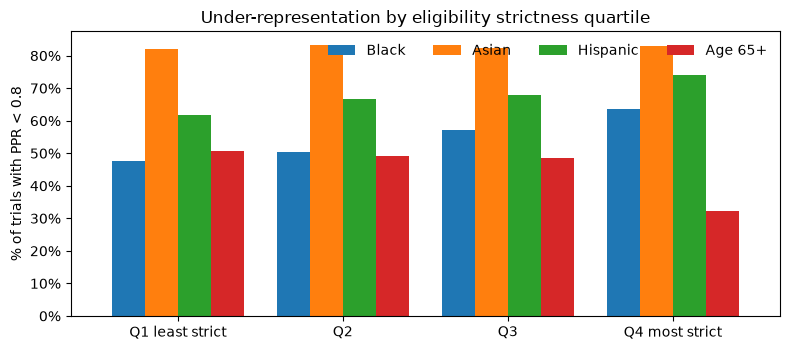

,Black,Asian,Hispanic,Age 65+
strict_q,,,,
Q1 least strict,0.477,0.820,0.617,0.507
Q2,0.502,0.833,0.666,0.492
Q3,0.570,0.825,0.678,0.485
Q4 most strict,0.636,0.830,0.739,0.324


In [13]:
# ---- under-representation by strictness quartile (descriptive, for slides) ---------------
df["strict_q"] = pd.qcut(df["strictness"], 4, labels=["Q1 least strict", "Q2", "Q3", "Q4 most strict"])
under = pd.DataFrame({g: df.groupby("strict_q", observed=True)[c].apply(lambda x: (x.dropna() < UNDER).mean())
                      for g, c in PPR.items() if g in ["Black", "Hispanic", "Asian", "Age 65+"]})
ax = under.plot(kind="bar", figsize=(8, 3.6), rot=0, width=0.8)
ax.set_ylabel(f"% of trials with PPR < {UNDER}"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Under-representation by eligibility strictness quartile"); ax.legend(frameon=False, ncol=4)
plt.tight_layout(); plt.savefig(FIG / "rep_under_by_strictness.png", dpi=200); plt.show()
under.round(3)

In [14]:
df.to_parquet(PROC / "representation_ppr.parquet", index=False)
print("Saved data/processed/representation_ppr.parquet, ppr_summary.csv, ppr_strictness_models.csv")

Saved data/processed/representation_ppr.parquet, ppr_summary.csv, ppr_strictness_models.csv


## Limitations (for the report)

- **Whole-trial demographics vs. local counties:** participants may travel from outside the site county,
  so county shares approximate, not measure, the reachable population.
- **Population vs. disease burden:** the comparison is with the general population, not the population
  with the condition studied. A disease-prevalence benchmark would differ (for example, older adults for
  cardiovascular trials). Read results as gaps relative to the local community.
- **Race categories:** ACS "Some other race" (often chosen by Hispanic respondents) has no NIH/OMB
  equivalent, so it is dropped from the Census denominator.
- **ACS timing:** one 5-year ACS vintage (2016–2020) is used for trials starting 2008–2020.
- **Selection:** only trials that posted standard NIH/OMB demographics are included, mostly completed
  industry and NIH trials; this is not a random sample of all trials.
- **Association, not causation:** strictness may track disease area and trial type beyond the adjusted covariates.